# Reproduce the paper: a dynamic stage–discharge rating at Bweramule, Semliki River

**Kakooza, C., Nafula, M., Kasibante, G., Waiswa, F. and Zaake, B. (2026).** *A dynamic stage–discharge rating for a migrating
tropical river: Kalman-filtered rating shifts and their uncertainty at Bweramule, Semliki River, Uganda.* Preprint, Zenodo,
https://doi.org/10.5281/zenodo.24367492

Run it top to bottom (*Run all*); it needs only `numpy` and `matplotlib` and takes a few seconds, locally or in Google Colab
([open in Colab](https://colab.research.google.com/github/Kaitale/semliki-sem9.10-dynamic-rating/blob/main/reproduce_paper.ipynb)).

| Step | What it reproduces |
|---|---|
| 1 | the fitted model state of 4 October 2026 (drift rate, gauging error, shift and its standard deviation) |
| 2 | Table 4 (stage for a given flow) and Table 5 (flow for a given stage) with their 90 % bands |
| 3 | Fig. 5: how the band grows without a gauging, and what one new gauging buys |
| 4 | the Jones loop correction at the observed rates of stage change (Section 4.5) |
| 5 | the whole method end to end — maximum-likelihood drift rate, Kalman filter, smoother, fixed-versus-dynamic comparison — on a synthetic record built with the paper's parameters |
| 6 | the same on your own gaugings (`MY_GAUGINGS = "file.csv"`) |

The 191 Bweramule gaugings are held by the Ministry of Water and Environment, Uganda, and are available on request; with them,
step 6 reproduces Table 3 and Figs. 2–3 of the paper.

## 0. Set-up

In [1]:
import os, sys, csv, math, datetime as dt, urllib.request
RAW = "https://raw.githubusercontent.com/Kaitale/semliki-sem9.10-dynamic-rating/main/"
for f in ("semliki_dynrating.py", "rating_R2026-10_table.csv"):
    if not os.path.exists(f):
        print("downloading", f); urllib.request.urlretrieve(RAW + f, f)
import numpy as np
import matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath("."))
import semliki_dynrating as D
OUT = os.path.abspath("outputs"); os.makedirs(OUT, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#E6EBEF"})

## 1. The model state of 4 October 2026

The rating at time *t* is the installed rating R2026-10 moved by a stage shift δ(*t*): *Q*(*h*, *t*) = *Q*<sub>base</sub>(*h* − δ(*t*)).
δ follows a random walk with variance rate *q*; each gauging measures δ with an error set by the discharge error σ<sub>Q</sub>.
*q* and the current-meter σ<sub>Q</sub> were estimated by maximum likelihood on the 176 current-meter gaugings of 1950–1975;
the ADCP gaugings of 2024–2025 (σ<sub>Q</sub> = 3 %) then fix the modern shift.

In [2]:
Q_DRIFT = 0.004626          # m2 per year  ->  sqrt(q) = 6.8 cm per sqrt(year)
SIGMA_CM = 0.0423           # current-meter gauging error (1 sd, relative), 1950-75
SIGMA_ADCP = 0.03           # ADCP gauging error (1 sd, relative)
SHIFT = 0.0069              # smoothed shift on R2026-10 after the last gauging (m)
SD_LAST = 0.0361            # its standard deviation on the day of the last gauging (m)
LAST, ISSUE = dt.date(2025, 9, 24), dt.date(2026, 10, 4)
S0, WIDTH = 0.00034, 107.0  # bed slope (HEC-RAS inverts) and top width at the gauge (ADCP section, 9 Mar 2025)

rows = list(csv.DictReader(open("rating_R2026-10_table.csv")))
BH = np.array([float(r["gauge_m"]) for r in rows]); BQ = np.array([float(r["Q_m3s"]) for r in rows])
age = (ISSUE - LAST).days
SD_NOW = math.sqrt(SD_LAST ** 2 + Q_DRIFT * age / D.YEAR)
R = D.Rating(BH, BQ, SHIFT, SD_NOW)
print("drift rate %.3f m per sqrt(year); %d days since the last gauging" % (math.sqrt(Q_DRIFT), age))
print("shift %+.1f cm; 90 %% stage band +-%.2f m at the last gauging, +-%.2f m on %s" % (100 * SHIFT, D.Z90 * SD_LAST, D.Z90 * SD_NOW, ISSUE))

drift rate 0.068 m per sqrt(year); 375 days since the last gauging
shift +0.7 cm; 90 % stage band +-0.06 m at the last gauging, +-0.13 m on 2026-10-04


## 2. The rating on 4 October 2026 (Tables 4 and 5)

In [3]:
print("Table 4. Stage on the Bweramule ADCP staff gauge for a given flow")
print("%10s %14s %18s %22s" % ("flow m3/s", "R2026-10 (m)", "dynamic mean (m)", "90 % band (m)"))
for Q in (150, 200, 250, 300, 350, 400, 450):
    h, lo, hi = R.stage(Q); hb = float(np.interp(Q, BQ, BH))
    print("%10d %14.2f %18.2f %14.2f - %.2f" % (Q, hb, h, lo, hi))
print("\nTable 5. Flow for a given stage")
print("%10s %20s %20s %16s" % ("stage m", "dynamic mean m3/s", "90 % band m3/s", "band in flow"))
for h in (17.0, 17.5, 18.0, 18.5, 19.0):
    q, lo, hi, _ = R.flow(h)
    print("%10.1f %20.1f %13.0f - %.0f %9.1f / %+.1f %%" % (h, q, lo, hi, 100 * (lo / q - 1), 100 * (hi / q - 1)))

Table 4. Stage on the Bweramule ADCP staff gauge for a given flow
 flow m3/s   R2026-10 (m)   dynamic mean (m)          90 % band (m)
       150          16.56              16.56          16.44 - 16.69
       200          17.08              17.08          16.96 - 17.21
       250          17.52              17.53          17.40 - 17.66
       300          17.92              17.92          17.79 - 18.05
       350          18.26              18.27          18.14 - 18.40
       400          18.58              18.58          18.46 - 18.71
       450          18.87              18.88          18.75 - 19.01

Table 5. Flow for a given stage
   stage m    dynamic mean m3/s       90 % band m3/s     band in flow
      17.0                191.4           179 - 205      -6.7 / +7.0 %
      17.5                246.6           232 - 262      -6.1 / +6.3 %
      18.0                310.5           293 - 328      -5.5 / +5.7 %
      18.5                386.5           366 - 407      -5.4 / +5.4 %
   

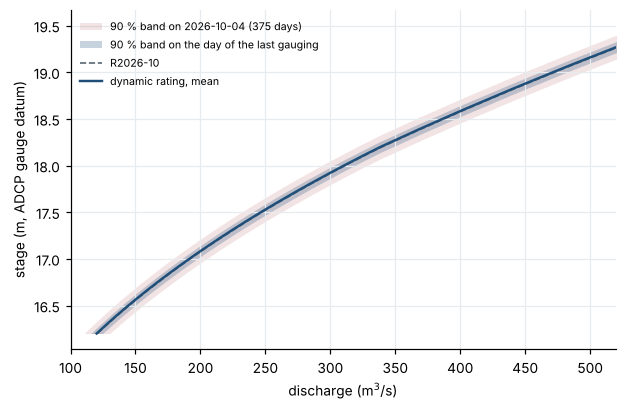

In [4]:
hh = np.arange(16.2, 19.5, 0.01)
f_now = np.array([R.flow(h)[:3] for h in hh]); R0 = D.Rating(BH, BQ, SHIFT, SD_LAST); f_0 = np.array([R0.flow(h)[:3] for h in hh])
fig, ax = plt.subplots(figsize=(6.4, 4.0))
ax.fill_betweenx(hh, f_now[:, 1], f_now[:, 2], color="#9B2226", alpha=.12, lw=0, label="90 %% band on %s (%d days)" % (ISSUE, age))
ax.fill_betweenx(hh, f_0[:, 1], f_0[:, 2], color="#1F4E79", alpha=.25, lw=0, label="90 % band on the day of the last gauging")
ax.plot(np.interp(hh, BH, BQ), hh, "--", color="#5A6A76", lw=1.1, label="R2026-10")
ax.plot(f_now[:, 0], hh, color="#1F4E79", lw=1.6, label="dynamic rating, mean")
ax.set_xlim(100, 520); ax.set_xlabel("discharge (m$^3$/s)"); ax.set_ylabel("stage (m, ADCP gauge datum)"); ax.legend(fontsize=7, frameon=False)
fig.savefig(os.path.join(OUT, "rating_today.png"), dpi=300, bbox_inches="tight"); plt.show()

## 3. How fast the knowledge decays (Fig. 5)
The band grows with the square root of the time since the last gauging; read the other way it is a gauging schedule.

after  0 months: +-0.06 m  (+-2.9 % in flow at 17.5 m)
after  6 months: +-0.10 m  (+-4.8 % in flow at 17.5 m)
after 12 months: +-0.13 m  (+-6.1 % in flow at 17.5 m)
after 24 months: +-0.17 m  (+-8.1 % in flow at 17.5 m)
after 48 months: +-0.23 m  (+-11.1 % in flow at 17.5 m)
to stay within +-0.10 m: gauge every 6 months
to stay within +-0.15 m: gauge every 18 months
one ADCP gauging at 250 m3/s on 2026-10-04 would bring the band to +-0.08 m


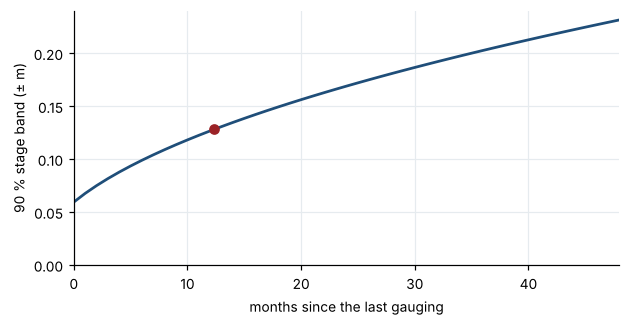

In [5]:
mo = np.arange(0, 49)
band = D.Z90 * np.sqrt(SD_LAST ** 2 + Q_DRIFT * mo / 12)
dlnq_dh = lambda h: 1 / (np.interp(h, BH, BQ) / R.dqdh(h))          # relative flow change per metre of stage
for m in (0, 6, 12, 24, 48):
    b = D.Z90 * math.sqrt(SD_LAST ** 2 + Q_DRIFT * m / 12)
    print("after %2d months: +-%.2f m  (+-%.1f %% in flow at 17.5 m)" % (m, b, 100 * b * dlnq_dh(17.5)))
for target in (0.10, 0.15):
    m = 12 * ((target / D.Z90) ** 2 - SD_LAST ** 2) / Q_DRIFT
    print("to stay within +-%.2f m: gauge every %.0f months" % (target, m))
sd_g = SIGMA_ADCP / dlnq_dh(float(np.interp(250.0, BQ, BH)))        # stage error of one ADCP gauging (m)
print("one ADCP gauging at 250 m3/s on %s would bring the band to +-%.2f m" % (ISSUE, D.band_after_gauging(SD_NOW, sd_g)))
fig, ax = plt.subplots(figsize=(6.4, 3.0))
ax.plot(mo, band, color="#1F4E79", lw=1.8); ax.scatter([age / 30.44], [D.Z90 * SD_NOW], color="#9B2226", zorder=5)
ax.set_xlabel("months since the last gauging"); ax.set_ylabel("90 % stage band (± m)"); ax.set_xlim(0, 48); ax.set_ylim(0, None)
fig.savefig(os.path.join(OUT, "band_growth.png"), dpi=300, bbox_inches="tight"); plt.show()

## 4. The loop correction (Jones)
Rates of stage change from the 2023–2025 telemetry (hourly, despiked): median 0.039, 90th percentile 0.15 and 99th percentile 0.39 m/day.

In [6]:
for lab, r in (("median", 0.039), ("90th percentile", 0.150), ("99th percentile", 0.391)):
    print("%-16s %.3f m/day -> Jones correction at 17.5 m: %+.2f %%" % (lab, r, 100 * (D.jones(R, 17.5, r, S0, WIDTH) - 1)))
h_mean = 16.9    # mean stage of the HEC-RAS hindcast at the gauge section
slope = math.log(D.jones(R, h_mean, 0.5, S0, WIDTH)) - math.log(D.jones(R, h_mean, -0.5, S0, WIDTH))
print("Jones slope at %.1f m: %.1f %% per m/day (the unsteady HEC-RAS hindcast gives 2.0 %% per m/day)" % (h_mean, 100 * slope))

median           0.039 m/day -> Jones correction at 17.5 m: +0.06 %
90th percentile  0.150 m/day -> Jones correction at 17.5 m: +0.23 %
99th percentile  0.391 m/day -> Jones correction at 17.5 m: +0.60 %
Jones slope at 16.9 m: 1.8 % per m/day (the unsteady HEC-RAS hindcast gives 2.0 % per m/day)


## 5. The method end to end, on a synthetic record

The real gaugings are not redistributed, so this step builds a record with the same sampling as Bweramule (176 gaugings
over 1950–1975 at 50–320 m³/s, then 11 in 2024–2025) and the paper's parameters (√*q* = 6.8 cm/√yr, σ<sub>Q</sub> = 4.2 %), and
runs the full estimation: maximum likelihood of *q* and σ<sub>Q</sub>, the Kalman filter and Rauch–Tung–Striebel smoother, and the
fixed-versus-dynamic comparison of Table 3. Change `SEED` to see the sampling spread of the estimates.

In [7]:
SEED = 42
rng = np.random.default_rng(SEED)
q_of_h, h_of_q, dh_dlnq = D.power_rating(8.863, 7.979, 2.563)        # Rating B on the old plate (1961-2012)
dates = sorted(dt.date(1950, 2, 1) + dt.timedelta(days=int(x)) for x in rng.uniform(0, 25.5 * 365.25, 176))
shift, last, G = -0.17, dates[0], []
for d in dates:
    shift += rng.normal(0, math.sqrt(Q_DRIFT * (d - last).days / D.YEAR)); last = d
    Q = float(rng.uniform(55, 300)); G.append(dict(date=d, h=float(h_of_q(Q)) + shift, Q=Q * math.exp(rng.normal(0, SIGMA_CM)), true=shift))
t = [(g["date"] - G[0]["date"]).days / D.YEAR for g in G]
F = D.fit_drift(t, [g["h"] for g in G], [g["Q"] for g in G], h_of_q, dh_dlnq)
print("true values: 0.068 m/sqrt(yr), 4.2 %")
w = [D.Z90 * math.sqrt(r[3]) for r in F["filter"]][5:]
print("\n%-44s %10s %10s" % ("", "dynamic", "fixed"))
print("%-44s %10.1f %10.1f" % ("log-likelihood", F["loglik"], F["loglik_static"]))
print("%-44s %10.1f %10.1f" % ("AIC", F["aic"], F["aic_static"]))
print("%-44s %9.1f%% %9.1f%%" % ("gauging scatter about the rating (1 sd)", 100 * F["sigma_gauging"], 100 * F["sigma_static"]))
print("%-44s %9.2f m" % ("average 90 % band on the next gauging", np.mean(w)))
print("%-44s %9.0f%%" % ("gaugings inside it", 100 * F["cover90"]))

drift rate 0.049 m per sqrt(year); gauging error 4.7 %; loglik 240.2 (fixed rating 128.7); AIC -476 vs -255; one-step z sd 0.99, 94 % inside the 90 % band
true values: 0.068 m/sqrt(yr), 4.2 %

                                                dynamic      fixed
log-likelihood                                    240.2      128.7
AIC                                              -476.4     -255.4
gauging scatter about the rating (1 sd)            4.7%      10.4%
average 90 % band on the next gauging             0.10 m
gaugings inside it                                  94%


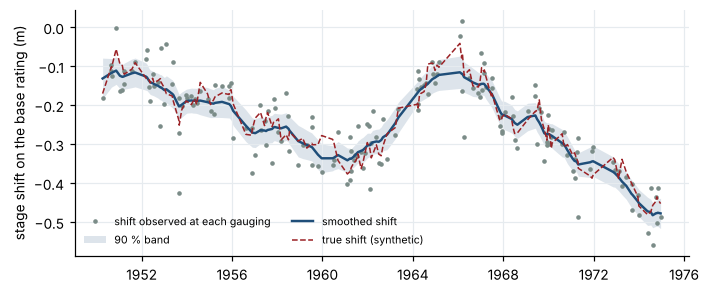

In [8]:
dd = [g["date"] for g in G]; xs, ss = np.array(F["smoothed_shift"]), np.array(F["smoothed_sd"])
fig, ax = plt.subplots(figsize=(7.2, 2.9))
ax.plot(dd, F["obs_shift"], ".", ms=4, color="#7B8C88", label="shift observed at each gauging")
ax.fill_between(dd, xs - D.Z90 * ss, xs + D.Z90 * ss, color="#1F4E79", alpha=.15, lw=0, label="90 % band")
ax.plot(dd, xs, color="#1F4E79", lw=1.6, label="smoothed shift")
ax.plot(dd, [g["true"] for g in G], "--", color="#9B2226", lw=1, label="true shift (synthetic)")
ax.set_ylabel("stage shift on the base rating (m)"); ax.legend(fontsize=7, frameon=False, ncol=2)
fig.savefig(os.path.join(OUT, "synthetic_shift.png"), dpi=300, bbox_inches="tight"); plt.show()

## 6. Your own gaugings

Put a CSV with columns `date` (YYYY-MM-DD), `stage_m` and `Q_m3s` beside the notebook and set `MY_GAUGINGS`. Give the base rating
as a power law `Q = a (h − h0)^c` (`BASE`) or replace `h_of_q` and `dh_dlnq` with interpolation in your own table.
With the Bweramule current-meter gaugings of 1950–1975 on the old plate and Rating B, this cell reproduces Table 3 of the paper.

In [9]:
MY_GAUGINGS = None                 # e.g. "bweramule_gaugings.csv"
BASE = (8.863, 7.979, 2.563)       # Rating B, Bweramule old plate
if MY_GAUGINGS:
    rows = [r for r in csv.DictReader(open(MY_GAUGINGS))]
    d0 = dt.date.fromisoformat(rows[0]["date"][:10])
    tt = [(dt.date.fromisoformat(r["date"][:10]) - d0).days / D.YEAR for r in rows]
    _, hq, dk = D.power_rating(*BASE)
    FF = D.fit_drift(tt, [float(r["stage_m"]) for r in rows], [float(r["Q_m3s"]) for r in rows], hq, dk)
else:
    print("set MY_GAUGINGS to run on your own record")

set MY_GAUGINGS to run on your own record
